# Machine Fault Recognition — EfficientAT + CGAN Augmentation

**Architecture:** EfficientNet-B0 + AudioFrontend + Temporal Attention (from scratch)

**Key Improvements Over Baseline:**
- 🎯 **Conditional GAN (CGAN)** — generates synthetic Mel-spectrograms for minority abnormal classes (1,3,5)
- ⚖️ **Focal Loss + Hard Class Weights** — heavily penalises misclassification of abnormal classes
- 📊 **Asymmetric Label Smoothing** — less smoothing on minority classes to preserve gradients
- 🔁 **Two-Phase Training** — GAN pre-trains first, then classifier trains on real+synthetic data
- 🛑 **Reduced Dropout / Drop-Path** — val loss oscillated too much in baseline (over-regularised)

**Data:** Same DBSCAN cluster-aware split as baseline — ZERO leakage

In [1]:
!pip install -q timm torchaudio seaborn scikit-learn librosa

## 1 · Imports & Configuration

In [2]:
import os, re, time, warnings, gc
import torch, torch.nn as nn, torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchaudio, torchaudio.transforms as TAT, timm
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, classification_report
warnings.filterwarnings('ignore')

# ── Reproducibility ──────────────────────────────────────────────
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

# ── Paths ────────────────────────────────────────────────────────
SAVE_DIR = '/kaggle/working/'
os.makedirs(SAVE_DIR, exist_ok=True)

CLUSTER_CSV_PATH = '/kaggle/input/datasets/abdallahayman03/dbscanresults/dbscan_per_class_results.csv'
NPY_DIR          = '/kaggle/input/datasets/mohamed3b3az/full-pre-processed-dataset-sound-classification/data/processed'
USE_PRECOMPUTED_NPY = True

# ── Audio / Mel ──────────────────────────────────────────────────
SAMPLE_RATE, DURATION_SEC = 16_000, 11.0
N_MELS, N_FFT, HOP_LENGTH = 128, 1024, 512
TARGET_FRAMES = 344

# ── Augmentation (train only) ────────────────────────────────────
AUG_FREQ_MASK      = 24
AUG_TIME_MASK      = 60
AUG_NOISE_STD      = 0.005
AUG_GAIN_RANGE     = (0.9, 1.1)
AUG_TIME_SHIFT_MAX = 12
MIXUP_ALPHA        = 0.3   # slightly higher to help minority classes

# ── Model ────────────────────────────────────────────────────────
D_MODEL            = 128
NHEAD              = 4
TRANSFORMER_LAYERS = 2
# ⬇ Reduced vs baseline (val loss was oscillating = over-regularised)
DROPOUT            = 0.3
DROP_PATH_RATE     = 0.05
LABEL_SMOOTHING    = 0.05   # ⬇ Less smoothing keeps minority-class gradients sharper
WEIGHT_DECAY       = 5e-3

# ── Focal Loss ───────────────────────────────────────────────────
FOCAL_GAMMA        = 2.0   # focus on hard examples
# Class weights: abnormal classes (1,3,5) get 3-4× the weight of normals
# Derived from inverse-frequency but capped and hand-tuned for abnormals
CLASS_WEIGHTS_RAW  = [1.0, 4.0, 1.0, 4.5, 1.0, 2.5]  # [M1N, M1A, M2N, M2A, M3N, M3A]

# ── GAN ─────────────────────────────────────────────────────────
GAN_LATENT_DIM     = 128
GAN_EPOCHS         = 30        # GAN trains first, independently
GAN_LR_G           = 2e-4
GAN_LR_D           = 1e-4
GAN_BATCH_SIZE     = 16
# GAN generator — prefer pre-trained from dataset, fall back to working dir
_GAN_INPUT  = '/kaggle/input/datasets/mohammadbahgat/bntmrn/cgan_generator.pt'
GAN_LOAD    = _GAN_INPUT if os.path.exists(_GAN_INPUT) else None  # for loading only
GAN_SAVE    = os.path.join(SAVE_DIR, 'cgan_generator.pt')  # ALWAYS save to writable working dir
# How many synthetic samples to generate per minority class
GAN_SYNTH_PER_CLASS = 400      # injected into training set
MINORITY_CLASSES    = [1, 3, 5] # M1 Abnormal, M2 Abnormal, M3 Abnormal

# ── Classifier Training ──────────────────────────────────────────
BATCH_SIZE   = 32
EPOCHS       = 30
LR           = 1e-3
NUM_CLASSES  = 6
NUM_WORKERS  = 0
# Best classifier — prefer pre-trained from dataset, fall back to working dir
_MODEL_INPUT = '/kaggle/input/datasets/mohammadbahgat/bntmrn/best_efficientat_gan.pt'
MODEL_LOAD   = _MODEL_INPUT if os.path.exists(_MODEL_INPUT) else None  # for loading only
MODEL_SAVE   = os.path.join(SAVE_DIR, 'best_efficientat_gan.pt')  # ALWAYS save to writable working dir
# Auto-resume from best model if it exists (training will run for 10 epochs)
RESUME_CHECKPOINT = MODEL_LOAD if MODEL_LOAD and os.path.exists(MODEL_LOAD) else (MODEL_SAVE if os.path.exists(MODEL_SAVE) else '')

# If best model already exists, only fine-tune for 10 more epochs
EPOCHS = 10 if ((MODEL_LOAD and os.path.exists(MODEL_LOAD)) or os.path.exists(MODEL_SAVE)) else EPOCHS

CLASS_NAMES  = ['M1 Normal','M1 Abnormal','M2 Normal','M2 Abnormal','M3 Normal','M3 Abnormal']
DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f'  GPU [{i}] {torch.cuda.get_device_name(i)}')

Device: cuda
  GPU [0] Tesla T4
  GPU [1] Tesla T4


## 2 · Data Loading & STRICT Grouped Split
*(Identical to baseline — zero leakage via DBSCAN cluster-aware split)*

In [3]:
def wav_path_to_npy(wav_path: str) -> str:
    m = re.search(r'Machine\s+(\d+)', wav_path, re.IGNORECASE)
    machine_num = m.group(1) if m else 'X'
    condition   = 'abnormal' if 'Abnormal' in wav_path else 'normal'
    file_idx    = Path(wav_path).stem
    return os.path.join(NPY_DIR, f"{machine_num}_{condition}_{file_idx}.npy")

print(f'Loading cluster CSV: {CLUSTER_CSV_PATH}')
df_all = pd.read_csv(CLUSTER_CSV_PATH)

missing = {'file_path','label','cluster'} - set(df_all.columns)
if missing: raise ValueError(f'CSV missing columns: {missing}')
print(f'Raw rows: {len(df_all):,} | Clusters (incl noise): {df_all["cluster"].nunique()}')

df_clean = df_all[df_all['cluster'] != -1].reset_index(drop=True)
print(f'After noise drop: {len(df_clean):,} rows, {df_clean["cluster"].nunique()} clusters')

df_clean['file_path'] = df_clean['file_path'].apply(wav_path_to_npy)
n_exist = df_clean['file_path'].apply(os.path.exists).sum()
print(f'.npy files found: {n_exist:,}/{len(df_clean):,} ({100*n_exist/len(df_clean):.1f}%)')
if n_exist/len(df_clean) < 0.95:
    print('WARNING: >5% files missing!')

if df_clean['label'].dtype == object:
    label_map = {n:i for i,n in enumerate(CLASS_NAMES)}
    df_clean['label_int'] = df_clean['label'].map(label_map)
    if df_clean['label_int'].isna().any():
        lmap2 = {k.lower():v for k,v in label_map.items()}
        df_clean['label_int'] = df_clean['label'].str.lower().map(lmap2)
else:
    df_clean['label_int'] = df_clean['label'].astype(int)
assert not df_clean['label_int'].isna().any(), "Unmapped labels!"
print('Class distribution:'); print(df_clean.groupby('label_int').size().rename('count'))

cluster_label_counts = df_clean.groupby('cluster')['label_int'].nunique()
bad_clusters = cluster_label_counts[cluster_label_counts > 1]
if len(bad_clusters) > 0:
    raise ValueError(f'Clusters with mixed labels: {len(bad_clusters)}')
print('✅ Cluster purity check passed.')

rng = np.random.RandomState(SEED)
train_clusters, val_clusters, test_clusters = set(), set(), set()

for label, df_label in df_clean.groupby('label_int'):
    clusters = df_label['cluster'].unique(); rng.shuffle(clusters)
    n_total  = len(clusters)
    n_train  = max(1, int(round(0.70 * n_total)))
    n_val    = max(1, int(round(0.15 * n_total)))
    n_test   = max(1, n_total - n_train - n_val)
    if n_train + n_val + n_test > n_total:
        n_train = max(1, n_total - n_val - n_test)
    train_clusters.update(clusters[:n_train])
    val_clusters.update(clusters[n_train:n_train + n_val])
    test_clusters.update(clusters[n_train + n_val:n_train + n_val + n_test])

df_train = df_clean[df_clean['cluster'].isin(train_clusters)].reset_index(drop=True)
df_val   = df_clean[df_clean['cluster'].isin(val_clusters)].reset_index(drop=True)
df_test  = df_clean[df_clean['cluster'].isin(test_clusters)].reset_index(drop=True)

assert set(df_train['cluster']).isdisjoint(set(df_val['cluster'])), 'Train/Val overlap!'
assert set(df_train['cluster']).isdisjoint(set(df_test['cluster'])), 'Train/Test overlap!'
assert set(df_val['cluster']).isdisjoint(set(df_test['cluster'])), 'Val/Test overlap!'
print(f'\n✅ ZERO cluster leakage confirmed.')
print(f'  Train : {len(df_train):>6,} | {df_train["cluster"].nunique():>2} clusters')
print(f'  Val   : {len(df_val):>6,} | {df_val["cluster"].nunique():>2} clusters')
print(f'  Test  : {len(df_test):>6,} | {df_test["cluster"].nunique():>2} clusters')

Loading cluster CSV: /kaggle/input/datasets/abdallahayman03/dbscanresults/dbscan_per_class_results.csv
Raw rows: 56,236 | Clusters (incl noise): 93
After noise drop: 56,236 rows, 93 clusters
.npy files found: 56,236/56,236 (100.0%)
Class distribution:
label_int
0    16200
1     3176
2    16200
3     3240
4    14400
5     3020
Name: count, dtype: int64
✅ Cluster purity check passed.

✅ ZERO cluster leakage confirmed.
  Train : 35,668 | 64 clusters
  Val   : 10,670 | 13 clusters
  Test  :  9,898 | 16 clusters


## 3 · Dataset

In [4]:
class MachineAudioDataset(Dataset):
    """Real .npy Mel-spectrogram dataset with optional augmentation."""
    def __init__(self, dataframe, use_npy=True, augment=False):
        self.df      = dataframe.reset_index(drop=True)
        self.use_npy = use_npy
        self.augment = augment
        self.freq_mask = TAT.FrequencyMasking(freq_mask_param=AUG_FREQ_MASK)
        self.time_mask = TAT.TimeMasking(time_mask_param=AUG_TIME_MASK)

    def _wav_to_mel(self, path):
        y, sr = librosa.load(path, sr=SAMPLE_RATE, duration=DURATION_SEC, mono=True)
        tlen = int(SAMPLE_RATE * DURATION_SEC)
        y = np.pad(y, (0, max(0, tlen-len(y))))[:tlen]
        mel = librosa.feature.melspectrogram(y=y, sr=SAMPLE_RATE, n_fft=N_FFT,
                                             hop_length=HOP_LENGTH, n_mels=N_MELS, power=2.0)
        return librosa.power_to_db(mel, ref=np.max).astype(np.float32)

    @staticmethod
    def _load_npy(path):
        arr = np.load(path).astype(np.float32)
        return arr[0] if arr.ndim == 3 else arr

    @staticmethod
    def _fix_time(mel):
        T = mel.shape[1]
        if T > TARGET_FRAMES: return mel[:, :TARGET_FRAMES]
        if T < TARGET_FRAMES: return np.pad(mel, ((0,0),(0,TARGET_FRAMES-T)))
        return mel

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        label = int(row['label_int'])
        try:
            mel_np = self._load_npy(row['file_path']) if self.use_npy else self._wav_to_mel(row['file_path'])
        except Exception as e:
            print(f'[WARN] {row["file_path"]}: {e}. Using zeros.')
            mel_np = np.zeros((N_MELS, TARGET_FRAMES), dtype=np.float32)
        mel_np = self._fix_time(mel_np)
        lo, hi = mel_np.min(), mel_np.max()
        if hi > lo: mel_np = 2.0*(mel_np-lo)/(hi-lo) - 1.0
        mel = torch.from_numpy(mel_np).unsqueeze(0)
        if self.augment:
            if AUG_GAIN_RANGE:
                mel *= float(np.random.uniform(*AUG_GAIN_RANGE))
            if AUG_NOISE_STD > 0:
                mel += torch.randn_like(mel) * float(AUG_NOISE_STD)
            if AUG_TIME_SHIFT_MAX > 0:
                shift = int(np.random.randint(-AUG_TIME_SHIFT_MAX, AUG_TIME_SHIFT_MAX + 1))
                if shift != 0: mel = torch.roll(mel, shifts=shift, dims=-1)
            mel = self.time_mask(self.freq_mask(mel)).clamp(-1.0, 1.0)
        return mel, label


class SyntheticDataset(Dataset):
    """Wraps pre-generated GAN tensors so they fit the same DataLoader pipeline."""
    def __init__(self, mels: torch.Tensor, labels: torch.Tensor):
        assert mels.shape[0] == labels.shape[0]
        self.mels   = mels
        self.labels = labels

    def __len__(self): return len(self.labels)

    def __getitem__(self, idx):
        return self.mels[idx], int(self.labels[idx])

## 4 · Conditional GAN (CGAN) for Minority Class Augmentation

**Why CGAN?**  
Classes 1, 3, 5 (all Abnormal) have 4–5× fewer samples than their Normal counterparts.  
The CGAN learns to synthesise realistic Mel-spectrograms conditioned on class label, so we can generate  
extra abnormal samples that the classifier trains on alongside real data.

**Architecture:**
- **Generator** — noise + class embedding → upsampled Mel (1×128×344)
- **Discriminator** — Mel + class embedding → real/fake score (PatchGAN-style)

In [5]:
# ── GAN Skip Check ──────────────────────────────────────────────
GAN_SKIP = GAN_LOAD and os.path.exists(GAN_LOAD)
if GAN_SKIP:
    print(f'⚡ Found existing generator at {GAN_LOAD} — skipping GAN training.')
else:
    print('No saved generator found — will train CGAN from scratch.')

# ─────────────────────────────────────────────────────────────────
#  CGAN — Generator
# ─────────────────────────────────────────────────────────────────
class ResBlock1D(nn.Module):
    """1-D residual block used inside the generator."""
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm1d(channels),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv1d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm1d(channels),
        )
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x):
        return self.act(x + self.block(x))


class CGANGenerator(nn.Module):
    """
    Noise [B, LATENT] + class embedding [B, EMB] -> Mel [B, 1, 128, 344]
    Upsample path: 1D conv across time, then reshape to 2D.
    """
    def __init__(self, latent_dim=128, num_classes=6, emb_dim=32, base_ch=256):
        super().__init__()
        self.latent_dim = latent_dim
        self.emb = nn.Embedding(num_classes, emb_dim)

        # Project noise + embedding to a small spatial representation
        self.proj = nn.Sequential(
            nn.Linear(latent_dim + emb_dim, base_ch * 11),
            nn.LeakyReLU(0.2, inplace=True),
        )   # -> [B, base_ch*11] -> reshaped to [B, base_ch, 11]

        self.base_ch = base_ch

        # 1D upsampling blocks (time axis: 11 -> 22 -> 43 -> 86 -> 172 -> 344)
        def up_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Upsample(scale_factor=2, mode='linear', align_corners=False),
                nn.Conv1d(in_ch, out_ch, 3, padding=1, bias=False),
                nn.BatchNorm1d(out_ch),
                nn.LeakyReLU(0.2, inplace=True),
            )

        self.up1 = up_block(base_ch,      base_ch)       # 11->22
        self.rb1 = ResBlock1D(base_ch)
        self.up2 = up_block(base_ch,      base_ch // 2)  # 22->44 (padded to 43 later)
        self.rb2 = ResBlock1D(base_ch // 2)
        self.up3 = up_block(base_ch // 2, base_ch // 4)  # 44->88 (padded to 86)
        self.rb3 = ResBlock1D(base_ch // 4)
        self.up4 = up_block(base_ch // 4, base_ch // 8)  # 88->176 (padded to 172)
        self.rb4 = ResBlock1D(base_ch // 8)
        self.up5 = up_block(base_ch // 8, 128)           # 176->352 (trimmed to 344)

        # Final: reshape time-dim sequence to [B,1,128,T]
        # Each time step in the 1D output becomes one freq column
        # After up5: [B, 128, ~352] -> take first 344 -> [B, 1, 128, 344]
        self.final = nn.Sequential(
            nn.Conv1d(128, 128, 3, padding=1),
            nn.Tanh(),
        )

    def forward(self, z, labels):
        e   = self.emb(labels)           # [B, emb_dim]
        x   = self.proj(torch.cat([z, e], dim=1))  # [B, base_ch*11]
        x   = x.view(x.size(0), self.base_ch, 11)  # [B, base_ch, 11]
        x   = self.rb1(self.up1(x))      # [B, base_ch,    22]
        x   = self.rb2(self.up2(x))      # [B, base_ch//2, 44]
        x   = self.rb3(self.up3(x))      # [B, base_ch//4, 88]
        x   = self.rb4(self.up4(x))      # [B, base_ch//8, 176]
        x   = self.up5(x)                # [B, 128, ~352]
        x   = x[:, :, :344]             # trim to [B, 128, 344]
        x   = self.final(x)              # [B, 128, 344]
        # Reshape: treat 128 channels as frequency bins -> [B,1,128,344]
        return x.unsqueeze(1)            # [B, 1, 128, 344]


# ─────────────────────────────────────────────────────────────────
#  CGAN — Discriminator (PatchGAN-style)
# ─────────────────────────────────────────────────────────────────
class CGANDiscriminator(nn.Module):
    """
    Real/Fake classifier conditioned on class label.
    Mel [B,1,128,344] + class embedding projected as extra channel -> scalar score.
    """
    def __init__(self, num_classes=6, emb_dim=32):
        super().__init__()
        self.emb = nn.Embedding(num_classes, emb_dim)
        # Project embedding to a spatial map matching Mel shape
        self.emb_proj = nn.Linear(emb_dim, N_MELS * TARGET_FRAMES)

        # Input: 2 channels (mel + projected embedding)
        def d_block(in_ch, out_ch, stride=2):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 4, stride=stride, padding=1, bias=False),
                nn.InstanceNorm2d(out_ch, affine=True),
                nn.LeakyReLU(0.2, inplace=True),
            )

        self.net = nn.Sequential(
            nn.Conv2d(2, 64, 4, stride=2, padding=1),  # no norm on first layer
            nn.LeakyReLU(0.2, inplace=True),
            d_block(64,  128),
            d_block(128, 256),
            d_block(256, 512, stride=1),
            nn.Conv2d(512, 1, 4, stride=1, padding=1),   # patch output
        )

    def forward(self, mel, labels):
        # mel: [B,1,128,344]
        e     = self.emb(labels)                                    # [B, emb_dim]
        e_map = self.emb_proj(e).view(-1, 1, N_MELS, TARGET_FRAMES) # [B,1,128,344]
        x     = torch.cat([mel, e_map], dim=1)                      # [B,2,128,344]
        return self.net(x)


def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Conv1d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.constant_(m.bias, 0)

if not GAN_SKIP:
    netG = CGANGenerator(latent_dim=GAN_LATENT_DIM, num_classes=NUM_CLASSES).to(DEVICE)
    netD = CGANDiscriminator(num_classes=NUM_CLASSES).to(DEVICE)
    netG.apply(weights_init); netD.apply(weights_init)
    print(f'Generator  params: {sum(p.numel() for p in netG.parameters()):,}')
    print(f'Discriminator params: {sum(p.numel() for p in netD.parameters()):,}')
else:
    # Load existing generator (no discriminator needed)
    netG = CGANGenerator(latent_dim=GAN_LATENT_DIM, num_classes=NUM_CLASSES).to(DEVICE)
    netG.load_state_dict(torch.load(GAN_LOAD, map_location=DEVICE, weights_only=True))
    netG.eval()
    netD = None
    print(f'✅ Generator loaded from {GAN_LOAD}')


⚡ Found existing generator at /kaggle/input/datasets/mohammadbahgat/bntmrn/cgan_generator.pt — skipping GAN training.
✅ Generator loaded from /kaggle/input/datasets/mohammadbahgat/bntmrn/cgan_generator.pt


## 5 · GAN Training (Minority Classes Only)

We train the CGAN **only on minority (abnormal) class samples** from the training split.  
Loss: **Hinge Loss** (more stable than BCE for spectrograms) with one-sided label smoothing.

In [6]:
if GAN_SKIP:
    print('⚡ GAN training skipped — using loaded generator.')
    # Still need df_minority for visualisation in next cell
    df_minority = df_train[df_train['label_int'].isin(MINORITY_CLASSES)].reset_index(drop=True)
    gan_ds = MachineAudioDataset(df_minority, use_npy=USE_PRECOMPUTED_NPY, augment=False)
    gan_history = {'G_loss': [], 'D_loss': []}  # empty — no training done
else:
    # Build a dataset with ONLY the minority classes for GAN training
    df_minority = df_train[df_train['label_int'].isin(MINORITY_CLASSES)].reset_index(drop=True)
    print(f'Minority samples for GAN: {len(df_minority):,}')
    print(df_minority.groupby('label_int').size())
    
    gan_ds = MachineAudioDataset(df_minority, use_npy=USE_PRECOMPUTED_NPY, augment=True)
    
    # Balanced sampler within minority classes
    min_counts = df_minority.groupby('label_int').size()
    min_sw = [1.0/min_counts.get(int(l),1) for l in df_minority['label_int']]
    min_sampler = WeightedRandomSampler(min_sw, num_samples=len(min_sw), replacement=True)
    gan_loader = DataLoader(gan_ds, batch_size=GAN_BATCH_SIZE, sampler=min_sampler,
                            num_workers=NUM_WORKERS, pin_memory=False, drop_last=True)
    
    opt_G = optim.Adam(netG.parameters(), lr=GAN_LR_G, betas=(0.5, 0.999))
    opt_D = optim.Adam(netD.parameters(), lr=GAN_LR_D, betas=(0.5, 0.999))
    
    # Hinge loss helpers
    def hinge_D(real_logits, fake_logits):
        return (F.relu(1.0 - real_logits) + F.relu(1.0 + fake_logits)).mean()
    
    def hinge_G(fake_logits):
        return (-fake_logits).mean()
    
    
    gan_history = {'G_loss': [], 'D_loss': []}
    
    print(f'\nTraining CGAN for {GAN_EPOCHS} epochs on {len(df_minority):,} minority samples...')
    print('='*60)
    
    for epoch in range(1, GAN_EPOCHS + 1):
        g_losses, d_losses = [], []
    
        for real_mel, real_labels in tqdm(gan_loader, desc=f'  GAN E{epoch:02d}', leave=False):
            real_mel    = real_mel.to(DEVICE)
            real_labels = real_labels.to(DEVICE)
            B = real_mel.size(0)
    
            # ── Train Discriminator ──────────────────────────────────
            netD.zero_grad()
            z           = torch.randn(B, GAN_LATENT_DIM, device=DEVICE)
            fake_mel    = netG(z, real_labels).detach()
            real_logits = netD(real_mel, real_labels)
            fake_logits = netD(fake_mel, real_labels)
            d_loss      = hinge_D(real_logits, fake_logits)
            d_loss.backward()
            opt_D.step()
            d_losses.append(d_loss.item())
            del fake_mel, real_logits, fake_logits, d_loss, z
    
            # ── Train Generator (2× per D step for stability) ────────
            for _ in range(2):
                netG.zero_grad()
                z        = torch.randn(B, GAN_LATENT_DIM, device=DEVICE)
                fake_mel = netG(z, real_labels)
                g_logits = netD(fake_mel, real_labels)
                g_loss   = hinge_G(g_logits)
                g_loss.backward()
                opt_G.step()
            g_losses.append(g_loss.item())
    
        mean_g = np.mean(g_losses); mean_d = np.mean(d_losses)
        gan_history['G_loss'].append(mean_g)
        gan_history['D_loss'].append(mean_d)
    
        if epoch % 5 == 0 or epoch == 1:
            print(f'  Epoch {epoch:02d}/{GAN_EPOCHS}  G={mean_g:.4f}  D={mean_d:.4f}')
        # Free memory each epoch to prevent OOM / kernel death
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    
    # Save generator
    torch.save(netG.state_dict(), GAN_SAVE)
    print(f'\nGenerator saved → {GAN_SAVE}')
    
    # Plot GAN training curves
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(gan_history['G_loss'], label='Generator Loss',     lw=2)
    ax.plot(gan_history['D_loss'], label='Discriminator Loss', lw=2, ls='--')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Hinge Loss')
    ax.set_title('CGAN Training — Minority Classes', fontweight='bold')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, 'gan_training_curves.png'), dpi=150, bbox_inches='tight')
    plt.show()

⚡ GAN training skipped — using loaded generator.


## 6 · Generate Synthetic Samples & Visualise

Generate `GAN_SYNTH_PER_CLASS` synthetic Mel-spectrograms per minority class  
and append them to the training set.

  Generated 400 samples for class 1 (M1 Abnormal)
  Generated 400 samples for class 3 (M2 Abnormal)
  Generated 400 samples for class 5 (M3 Abnormal)

Total synthetic samples: 1,200


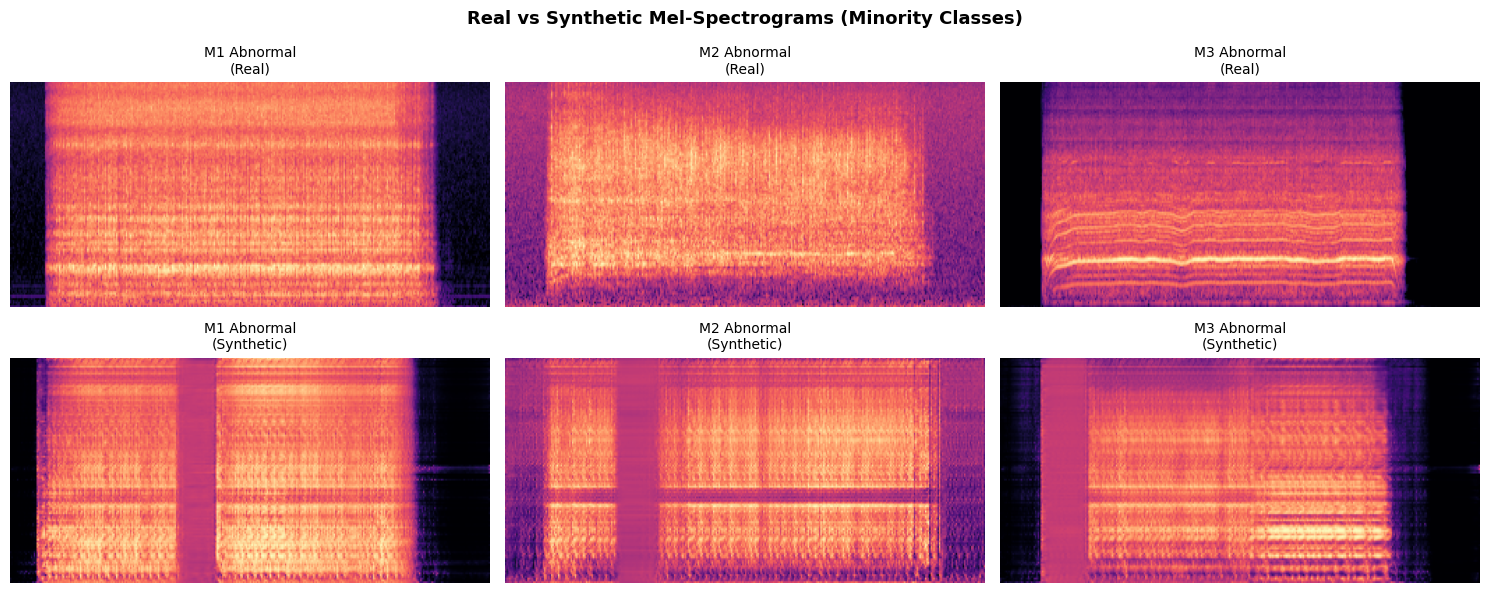

In [7]:
netG.eval()
synth_mels_list, synth_labels_list = [], []

CHUNK = 50  # generate in small chunks to avoid OOM
with torch.no_grad():
    for cls in MINORITY_CLASSES:
        cls_mels = []
        remaining = GAN_SYNTH_PER_CLASS
        while remaining > 0:
            n = min(CHUNK, remaining)
            z      = torch.randn(n, GAN_LATENT_DIM, device=DEVICE)
            labels_chunk = torch.full((n,), cls, dtype=torch.long, device=DEVICE)
            chunk_mels = netG(z, labels_chunk).cpu()
            cls_mels.append(chunk_mels)
            del z, labels_chunk, chunk_mels
            if torch.cuda.is_available(): torch.cuda.empty_cache()
            remaining -= n
        mels = torch.cat(cls_mels, dim=0)
        labels = torch.full((GAN_SYNTH_PER_CLASS,), cls, dtype=torch.long)
        synth_mels_list.append(mels)
        synth_labels_list.append(labels)
        print(f'  Generated {GAN_SYNTH_PER_CLASS} samples for class {cls} ({CLASS_NAMES[cls]})')
        gc.collect()

synth_mels   = torch.cat(synth_mels_list,   dim=0)  # [total_synth, 1, 128, 344]
synth_labels = torch.cat(synth_labels_list, dim=0)
print(f'\nTotal synthetic samples: {len(synth_mels):,}')
# Free GPU memory used during generation
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

# ── Visualise a few synthetic vs real spectrograms ───────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for i, cls in enumerate(MINORITY_CLASSES):
    # Real sample
    real_idx = df_minority[df_minority['label_int'] == cls].index[0]
    real_mel_np, _ = gan_ds[real_idx]
    axes[0, i].imshow(real_mel_np.squeeze().numpy(), aspect='auto', origin='lower', cmap='magma')
    axes[0, i].set_title(f'{CLASS_NAMES[cls]}\n(Real)', fontsize=10)
    axes[0, i].axis('off')

    # Synthetic sample
    syn_idx = (synth_labels == cls).nonzero(as_tuple=True)[0][0].item()
    axes[1, i].imshow(synth_mels[syn_idx].squeeze().numpy(), aspect='auto', origin='lower', cmap='magma')
    axes[1, i].set_title(f'{CLASS_NAMES[cls]}\n(Synthetic)', fontsize=10)
    axes[1, i].axis('off')

plt.suptitle('Real vs Synthetic Mel-Spectrograms (Minority Classes)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'gan_real_vs_synthetic.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7 · DataLoaders (Real + Synthetic Combined)

In [8]:
from torch.utils.data import ConcatDataset

real_train_ds  = MachineAudioDataset(df_train, use_npy=USE_PRECOMPUTED_NPY, augment=True)
synth_ds       = SyntheticDataset(synth_mels, synth_labels)
combined_ds    = ConcatDataset([real_train_ds, synth_ds])

val_ds   = MachineAudioDataset(df_val,  use_npy=USE_PRECOMPUTED_NPY, augment=False)
test_ds  = MachineAudioDataset(df_test, use_npy=USE_PRECOMPUTED_NPY, augment=False)

# Build labels list for the combined dataset (real + synthetic)
real_labels_list = list(df_train['label_int'].astype(int))
synth_labels_list_int = synth_labels.tolist()
combined_labels = real_labels_list + synth_labels_list_int

# Class counts after combining
from collections import Counter
combined_counts = Counter(combined_labels)
print('Combined class distribution (real + synthetic):')
for c in range(NUM_CLASSES):
    print(f'  {CLASS_NAMES[c]:15s}: {combined_counts[c]:,}')

# WeightedRandomSampler on combined dataset
cw_inv = [1.0/combined_counts[c] for c in combined_labels]
sampler = WeightedRandomSampler(cw_inv, num_samples=len(cw_inv), replacement=True)

train_loader = DataLoader(combined_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS, pin_memory=False)
val_loader   = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=False)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=False)

print(f'\nTrain batches (real+synth): {len(train_loader):,}')
print(f'Val   batches             : {len(val_loader):,}')
print(f'Test  batches             : {len(test_loader):,}')

Combined class distribution (real + synthetic):
  M1 Normal      : 11,038
  M1 Abnormal    : 2,726
  M2 Normal      : 11,275
  M2 Abnormal    : 1,352
  M3 Normal      : 8,147
  M3 Abnormal    : 2,330

Train batches (real+synth): 1,153
Val   batches             : 334
Test  batches             : 310


## 8 · Focal Loss + Class Weights

**Focal Loss** downweights easy majority-class examples so the classifier  
focuses its gradient budget on hard minority examples.  

**Class weights** multiply on top: abnormal classes (1,3,5) get 2.5–4.5× the base weight.

In [9]:
class FocalLoss(nn.Module):
    """
    Focal Loss = -alpha_t * (1 - p_t)^gamma * log(p_t)

    Args:
        weight  : per-class weights tensor (alpha)
        gamma   : focusing parameter (2.0 typical)
        smoothing: label smoothing applied BEFORE focal modulation
    """
    def __init__(self, weight=None, gamma=2.0, smoothing=0.05, reduction='mean'):
        super().__init__()
        self.register_buffer('weight', weight)  # [C]
        self.gamma     = gamma
        self.smoothing = smoothing
        self.reduction = reduction

    def forward(self, logits, targets):
        C = logits.size(1)
        # Smooth labels
        with torch.no_grad():
            one_hot = F.one_hot(targets, C).float()
            smooth  = one_hot * (1 - self.smoothing) + self.smoothing / C

        log_p = F.log_softmax(logits, dim=1)           # [B, C]
        p_t   = (log_p.exp() * one_hot).sum(1)         # p of TRUE class  [B]
        focal = (1 - p_t) ** self.gamma                # focusing weight  [B]

        # Cross-entropy with smooth targets
        ce    = -(smooth * log_p).sum(1)               # [B]

        # Per-sample class weight (alpha)
        if self.weight is not None:
            alpha_t = self.weight[targets]             # [B]
        else:
            alpha_t = torch.ones_like(p_t)

        loss = alpha_t * focal * ce

        if self.reduction == 'mean':  return loss.mean()
        if self.reduction == 'sum':   return loss.sum()
        return loss


# Normalise class weights
cw_tensor = torch.tensor(CLASS_WEIGHTS_RAW, dtype=torch.float32)
cw_tensor = cw_tensor / cw_tensor.sum() * NUM_CLASSES  # keep scale ~1
cw_tensor = cw_tensor.to(DEVICE)

print('Class weights for Focal Loss:')
for i, (name, w) in enumerate(zip(CLASS_NAMES, cw_tensor.tolist())):
    print(f'  [{i}] {name:15s}: {w:.3f}')

criterion = FocalLoss(weight=cw_tensor, gamma=FOCAL_GAMMA, smoothing=LABEL_SMOOTHING)

Class weights for Focal Loss:
  [0] M1 Normal      : 0.429
  [1] M1 Abnormal    : 1.714
  [2] M2 Normal      : 0.429
  [3] M2 Abnormal    : 1.929
  [4] M3 Normal      : 0.429
  [5] M3 Abnormal    : 1.071


## 9 · Model Architecture — EfficientAT (Trained from Scratch)

Same architecture as baseline with two key regularisation changes:
- **Dropout: 0.4 → 0.3** (val loss oscillated → was over-regularised)
- **Drop-path rate: 0.10 → 0.05** (same reason)

In [10]:
class AudioFrontend(nn.Module):
    """[B,1,F,T] -> [B,3,F,T] with delta + delta-delta."""
    def forward(self, x):
        d1 = torchaudio.functional.compute_deltas(x)
        d2 = torchaudio.functional.compute_deltas(d1)
        return torch.cat([x, d1, d2], dim=1)


class EfficientAT(nn.Module):
    def __init__(self, num_classes=6, pretrained=False, d_model=128, nhead=4,
                 num_layers=2, dropout=0.3, drop_path_rate=0.05):
        super().__init__()
        self.frontend    = AudioFrontend()
        self.backbone    = timm.create_model(
            'efficientnet_b0', pretrained=pretrained, in_chans=3, num_classes=0,
            global_pool='', drop_path_rate=drop_path_rate
        )
        self.height_pool = nn.AdaptiveAvgPool2d((1, None))
        self.proj        = nn.Sequential(
            nn.Conv1d(1280, d_model, 1, bias=False),
            nn.BatchNorm1d(d_model),
            nn.GELU()
        )
        enc = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
            dropout=dropout, batch_first=True, norm_first=True
        )
        self.attention = nn.TransformerEncoder(enc, num_layers=num_layers)
        self.head      = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes)
        )

    def forward(self, x):
        x = self.frontend(x)
        x = self.backbone(x)
        x = self.height_pool(x).squeeze(2)
        x = self.proj(x)
        x = self.attention(x.transpose(1,2)).transpose(1,2)
        return self.head(x)


model = EfficientAT(
    num_classes=NUM_CLASSES, pretrained=False,
    d_model=D_MODEL, nhead=NHEAD,
    num_layers=TRANSFORMER_LAYERS,
    dropout=DROPOUT, drop_path_rate=DROP_PATH_RATE
)
if torch.cuda.device_count() > 1:
    print(f'DataParallel across {torch.cuda.device_count()} GPUs')
    model = nn.DataParallel(model)
model = model.to(DEVICE)
print(f'Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

DataParallel across 2 GPUs
Trainable params: 4,568,962


## 10 · Training & Validation Helpers

In [11]:
def mixup_batch(x, y, alpha=0.3):
    if alpha is None or alpha <= 0:
        return x, y, y, 1.0
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    return lam*x + (1-lam)*x[idx], y, y[idx], lam


def train_one_epoch(model, loader, criterion, optimizer, scheduler):
    model.train()
    loss_sum, correct, total = 0.0, 0.0, 0
    for inputs, labels in tqdm(loader, desc='  Train', leave=False):
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        if MIXUP_ALPHA and MIXUP_ALPHA > 0:
            inputs, y_a, y_b, lam = mixup_batch(inputs, labels, MIXUP_ALPHA)
            out  = model(inputs)
            loss = lam * criterion(out, y_a) + (1 - lam) * criterion(out, y_b)
            preds = out.argmax(1)
            correct += (lam * preds.eq(y_a).sum().item() +
                        (1-lam) * preds.eq(y_b).sum().item())
        else:
            out  = model(inputs)
            loss = criterion(out, labels)
            correct += out.argmax(1).eq(labels).sum().item()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if scheduler: scheduler.step()
        loss_sum += loss.item() * inputs.size(0)
        total    += labels.size(0)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return loss_sum/total, 100.*correct/total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    preds_all, labels_all = [], []
    for inputs, labels in tqdm(loader, desc='  Eval ', leave=False):
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        out  = model(inputs)
        loss = criterion(out, labels)
        loss_sum += loss.item() * inputs.size(0)
        p = out.argmax(1)
        correct  += p.eq(labels).sum().item()
        total    += labels.size(0)
        preds_all.extend(p.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())
    gc.collect()
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return loss_sum/total, 100.*correct/total, preds_all, labels_all

## 11 · Train Classifier

In [12]:
if RESUME_CHECKPOINT and os.path.exists(RESUME_CHECKPOINT):
    print(f'🔄 Resuming from best checkpoint: {RESUME_CHECKPOINT}')
    print(f'   Training will run for {EPOCHS} additional epoch(s).')
    state = torch.load(RESUME_CHECKPOINT, map_location=DEVICE, weights_only=True)
    if isinstance(model, nn.DataParallel): model.module.load_state_dict(state)
    else: model.load_state_dict(state)
    # Start best_val_acc high so we only save if we genuinely improve
    # (evaluated properly before loop below)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))

class EarlyStopping:
    def __init__(self, patience=7, min_delta=0.001):
        self.patience=patience; self.min_delta=min_delta
        self.counter=0; self.best=float('inf'); self.stop=False
    def __call__(self, val_loss):
        if val_loss < self.best - self.min_delta:
            self.best=val_loss; self.counter=0
        else:
            self.counter += 1
            if self.counter >= self.patience: self.stop=True

early_stop   = EarlyStopping(patience=7)
history      = {'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
best_val_acc = 0.0

print(f'Classifier training: up to {EPOCHS} epochs')
print(f'Train={len(combined_ds):,} (real+synth) | Val={len(val_ds):,} | Test={len(test_ds):,}')
print('='*70)

for epoch in range(1, EPOCHS+1):
    t0 = time.time()
    tl, ta = train_one_epoch(model, train_loader, criterion, optimizer, scheduler)
    vl, va, _, _ = evaluate(model, val_loader, criterion)
    history['train_loss'].append(tl); history['val_loss'].append(vl)
    history['train_acc'].append(ta);  history['val_acc'].append(va)

    flag = ''
    if va > best_val_acc:
        best_val_acc = va
        state = model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()
        torch.save(state, MODEL_SAVE)
        flag = '  ✅ best saved'

    print(f'Epoch {epoch:02d}/{EPOCHS} [{time.time()-t0:.0f}s]  '
          f'Train Loss={tl:.4f} Acc={ta:.1f}%  |  Val Loss={vl:.4f} Acc={va:.1f}%{flag}')
    early_stop(vl)
    # Free memory after every epoch — prevents Kaggle kernel OOM
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    if early_stop.stop:
        print(f'Early stopping at epoch {epoch}.'); break

print(f'\nTraining complete. Best Val Acc: {best_val_acc:.2f}%')

🔄 Resuming from best checkpoint: /kaggle/input/datasets/mohammadbahgat/bntmrn/best_efficientat_gan.pt
   Training will run for 10 additional epoch(s).
Classifier training: up to 10 epochs
Train=36,868 (real+synth) | Val=10,670 | Test=9,898


  Train:   0%|          | 0/1153 [00:00<?, ?it/s]

  Eval :   0%|          | 0/334 [00:00<?, ?it/s]

Epoch 01/10 [516s]  Train Loss=0.1339 Acc=85.5%  |  Val Loss=0.0916 Acc=93.4%  ✅ best saved


  Train:   0%|          | 0/1153 [00:00<?, ?it/s]

...

  Eval :   0%|          | 0/334 [00:00<?, ?it/s]

Epoch 09/10 [483s]  Train Loss=0.0926 Acc=86.1%  |  Val Loss=0.0705 Acc=94.3%


  Train:   0%|          | 0/1153 [00:00<?, ?it/s]

  Eval :   0%|          | 0/334 [00:00<?, ?it/s]

Epoch 10/10 [518s]  Train Loss=0.0919 Acc=86.0%  |  Val Loss=0.0631 Acc=96.8%  ✅ best saved

Training complete. Best Val Acc: 96.83%


## 12 · Learning Curves

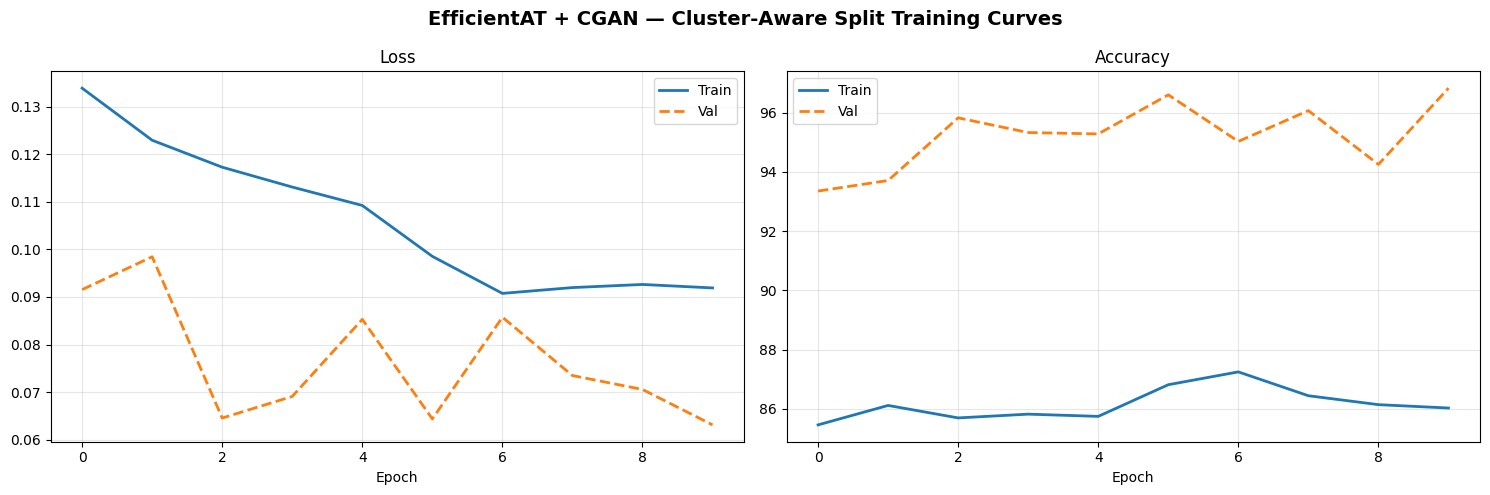

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(history['train_loss'], label='Train', lw=2)
ax1.plot(history['val_loss'],   label='Val',   lw=2, ls='--')
ax1.set_title('Loss'); ax1.set_xlabel('Epoch'); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(history['train_acc'], label='Train', lw=2)
ax2.plot(history['val_acc'],   label='Val',   lw=2, ls='--')
ax2.set_title('Accuracy'); ax2.set_xlabel('Epoch'); ax2.legend(); ax2.grid(alpha=0.3)
plt.suptitle('EfficientAT + CGAN — Cluster-Aware Split Training Curves',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 13 · Final Test Evaluation

In [14]:
print('Loading best checkpoint ...')
best_model = EfficientAT(
    num_classes=NUM_CLASSES, pretrained=False,
    d_model=D_MODEL, nhead=NHEAD,
    num_layers=TRANSFORMER_LAYERS,
    dropout=DROPOUT, drop_path_rate=DROP_PATH_RATE
)
ckpt_path = MODEL_SAVE if os.path.exists(MODEL_SAVE) else RESUME_CHECKPOINT
state = torch.load(ckpt_path, map_location=DEVICE, weights_only=True)
best_model.load_state_dict(state)
best_model = best_model.to(DEVICE)
best_model.eval()
print(f'  Loaded from: {ckpt_path}')

all_preds, all_labels = [], []
batch_times, running_loss, correct, total_samples = [], 0.0, 0, 0
criterion_eval = FocalLoss(weight=cw_tensor, gamma=FOCAL_GAMMA, smoothing=0.0)

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc='  Test '):
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t0 = time.perf_counter()
        outputs = best_model(inputs)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        batch_times.append(time.perf_counter() - t0)
        running_loss  += criterion_eval(outputs, labels).item() * inputs.size(0)
        preds          = outputs.argmax(1)
        correct       += preds.eq(labels).sum().item()
        total_samples += labels.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc  = 100.0 * correct / total_samples
test_loss = running_loss / total_samples
avg_ms    = 1000 * sum(batch_times) / len(batch_times)
per_sample_ms = avg_ms / BATCH_SIZE

print(f'\n{"="*60}')
print(f'  Test Loss : {test_loss:.4f}')
print(f'  Test Acc  : {test_acc:.2f}%')
print(f'  Avg batch latency : {avg_ms:.1f} ms  ({per_sample_ms:.2f} ms/sample)')
print(f'{"="*60}')

print('\nClassification Report:')
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4))

Loading best checkpoint ...
  Loaded from: /kaggle/working/best_efficientat_gan.pt


  Test :   0%|          | 0/310 [00:00<?, ?it/s]


  Test Loss : 0.0780
  Test Acc  : 89.38%
  Avg batch latency : 46.8 ms  (1.46 ms/sample)

Classification Report:
              precision    recall  f1-score   support

   M1 Normal     0.9209    0.9972    0.9576      2534
 M1 Abnormal     0.9774    0.6414    0.7746       608
   M2 Normal     0.9909    0.7424    0.8488      2341
 M2 Abnormal     0.4465    0.9683    0.6111       504
   M3 Normal     0.9898    0.9433    0.9660      3071
 M3 Abnormal     0.8226    0.9607    0.8863       840

    accuracy                         0.8938      9898
   macro avg     0.8580    0.8756    0.8407      9898
weighted avg     0.9298    0.8938    0.8995      9898



## 14 · Confusion Matrix

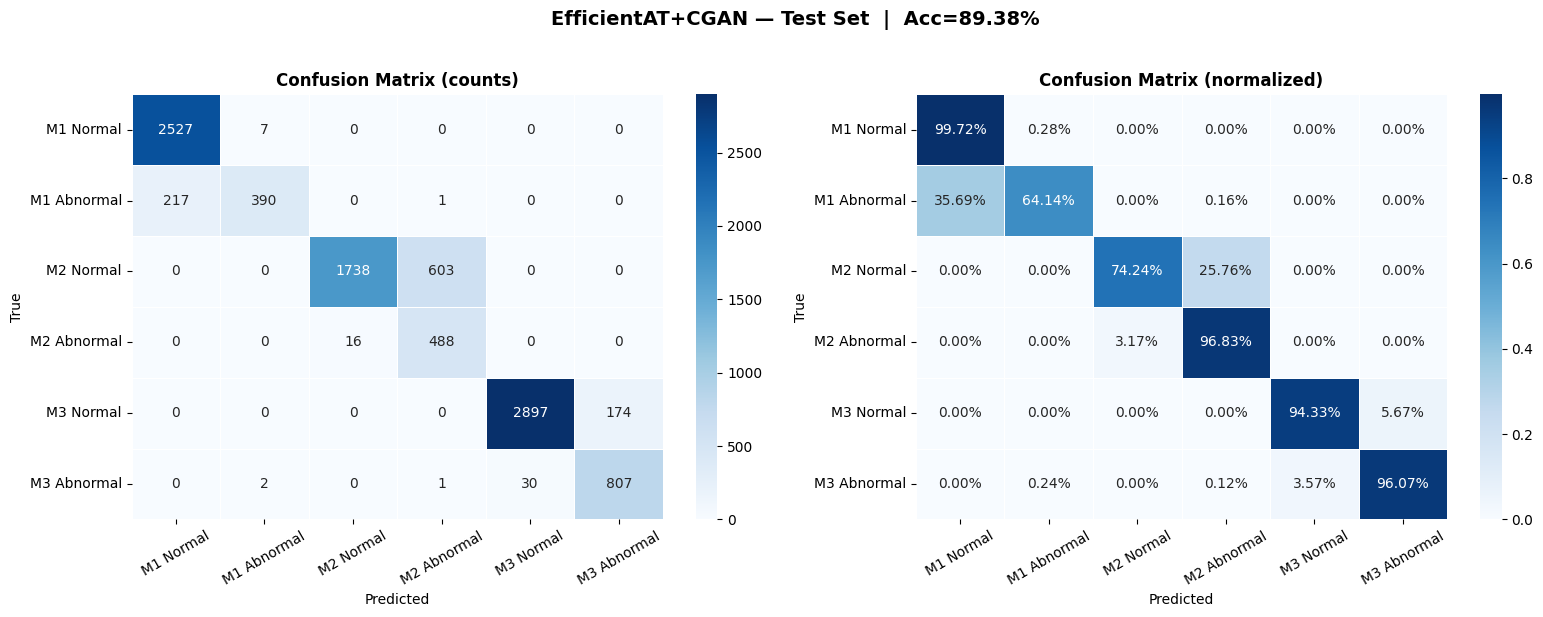

In [15]:
cm      = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, data, fmt, title in zip(
    axes,
    [cm, cm_norm],
    ['d', '.2%'],
    ['Confusion Matrix (counts)', 'Confusion Matrix (normalized)']
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=ax, linewidths=0.5)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(title, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle(f'EfficientAT+CGAN — Test Set  |  Acc={test_acc:.2f}%',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'test_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

## 15 · Per-Class F1 Comparison (Baseline vs This Run)

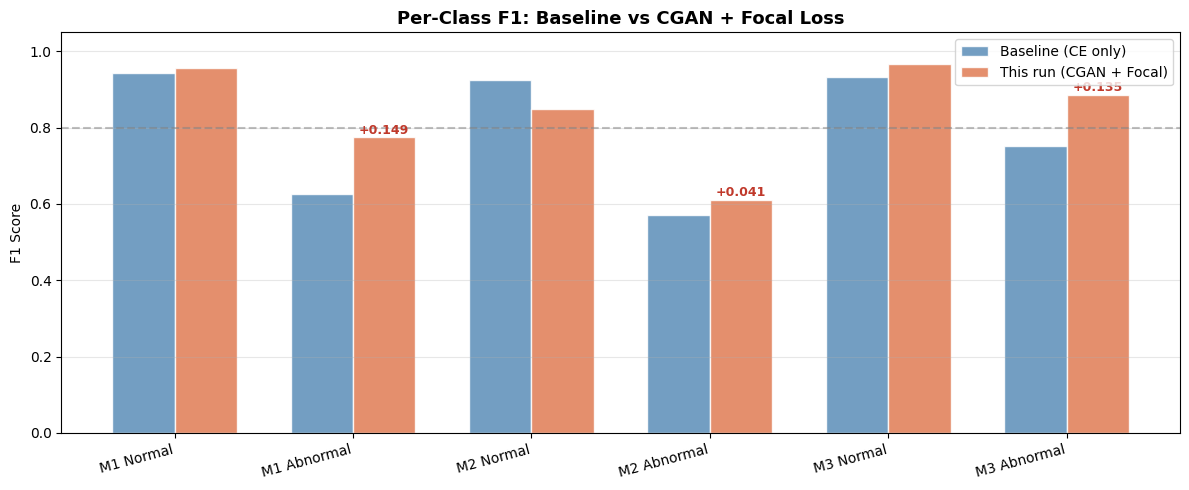


F1 delta (this - baseline) per class:
  M1 Normal      : baseline=0.9439  now=0.9576  (+0.0137)
  M1 Abnormal    : baseline=0.6258  now=0.7746  (+0.1488)
  M2 Normal      : baseline=0.9258  now=0.8488  (-0.0770)
  M2 Abnormal    : baseline=0.5701  now=0.6111  (+0.0410)
  M3 Normal      : baseline=0.9340  now=0.9660  (+0.0320)
  M3 Abnormal    : baseline=0.7515  now=0.8863  (+0.1348)


In [16]:
from sklearn.metrics import f1_score

# Baseline F1 scores (from your results)
baseline_f1 = [0.9439, 0.6258, 0.9258, 0.5701, 0.9340, 0.7515]
current_f1  = f1_score(all_labels, all_preds, average=None)

x    = np.arange(NUM_CLASSES)
w    = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - w/2, baseline_f1, w, label='Baseline (CE only)',
               color='#5b8db8', alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + w/2, current_f1,  w, label='This run (CGAN + Focal)',
               color='#e07b53', alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=15, ha='right')
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1.05)
ax.set_title('Per-Class F1: Baseline vs CGAN + Focal Loss', fontsize=13, fontweight='bold')
ax.legend()
ax.axhline(0.8, color='grey', ls='--', alpha=0.5, label='0.8 target')
ax.grid(axis='y', alpha=0.3)

# Annotate deltas for abnormal classes
for i in MINORITY_CLASSES:
    delta = current_f1[i] - baseline_f1[i]
    sign  = '+' if delta >= 0 else ''
    ax.annotate(f'{sign}{delta:.3f}',
                xy=(x[i] + w/2, current_f1[i] + 0.01),
                ha='center', fontsize=9, color='#c0392b', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'f1_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nF1 delta (this - baseline) per class:')
for i, name in enumerate(CLASS_NAMES):
    delta = current_f1[i] - baseline_f1[i]
    sign  = '+' if delta >= 0 else ''
    print(f'  {name:15s}: baseline={baseline_f1[i]:.4f}  now={current_f1[i]:.4f}  ({sign}{delta:.4f})')

## 16 · Save Predictions

In [17]:
df_preds = pd.DataFrame({'true_label': all_labels, 'pred_label': all_preds})
df_preds['true_name'] = df_preds['true_label'].map(dict(enumerate(CLASS_NAMES)))
df_preds['pred_name'] = df_preds['pred_label'].map(dict(enumerate(CLASS_NAMES)))
df_preds['correct']   = df_preds['true_label'] == df_preds['pred_label']
save_path = os.path.join(SAVE_DIR, 'test_predictions.csv')
df_preds.to_csv(save_path, index=False)
print(f'Predictions saved → {save_path}')
print(df_preds.head(10))

Predictions saved → /kaggle/working/test_predictions.csv
   true_label  pred_label    true_name    pred_name  correct
0           1           0  M1 Abnormal    M1 Normal    False
1           1           1  M1 Abnormal  M1 Abnormal     True
2           1           1  M1 Abnormal  M1 Abnormal     True
3           1           1  M1 Abnormal  M1 Abnormal     True
4           1           1  M1 Abnormal  M1 Abnormal     True
5           1           1  M1 Abnormal  M1 Abnormal     True
6           1           1  M1 Abnormal  M1 Abnormal     True
7           1           1  M1 Abnormal  M1 Abnormal     True
8           1           1  M1 Abnormal  M1 Abnormal     True
9           1           1  M1 Abnormal  M1 Abnormal     True
